# Analysis of Shot Types for TOP 20 WTA Players

**Author:** Galiya Galimova | Tennis Analyst

**Data:** 1979-2025 Match Charting Project (source: Jeff Sackmann's Match Charting Project [github](https://github.com/JeffSackmann/tennis_MatchChartingProject))

### Executive Summary

**Objective:** To analyze and compare the aggressiveness, shot-making efficiency and shot-type dominance among WTA Top 20 players (based on the ranking of May 27, 2026) using key performance metrics

**Method:** Exploratory data analysis

**Variables:**
- Shot types:
  - F - forehand groundstroke, B - backhand groundstroke, R - forehand slice, S - backhand slice, U - forehand drop shot, Y - backhand drop shot, L - forehand lob, M - backhand lob, V - forehand volley, Z - backhand volley, O - standard overhead (smash), P - backhand overhead, J - forehand swinging volley, K - backhand swinging volley, H - forehand half-volley, I - backhand half-volley
  - Gs - groundstroke (F+B), Sl - slice (R+S), Dr - drop shot (U+Y), Lo - lob (L+M), Vo - volley (V+Z), Ov - overhead (O+P), Sw - swinging volley (J+K), Hv - half-volley (H+I)
  - Base = Gs + Sl + Dr + Lo
  - Net = Vo + Ov + Sw + Hv
  - Fgs = F + R
  - Bgs = B + S
  - Fside = F + R + U + L + V + O + J + H
  - Bside = B + S + Y + M + Z + P + K + I
- Number of shots: total shots, winners, induced forced errors, unforced errors

**Key Insights:**
- Among the WTA Top 20 the most aggressive players are Amanda Anisimova, Aryna Sabalenka and Madison Keys, while the most controlled and defensive players are Elina Svitolina, Coco Gauff and Mirra Andreeva.
- Coco Gauff stands out as the only player whose backhand winner rate (6.3%) slightly exceeds her forehand winner rate (6.2%).
- Top winner rates by shot type:
  -    Forehand groundstroke - Aryna Sabalenka (13.1%)
  -    Backhand groundstroke - Amanda Anisimova (9.8%)
  -    Drop shot - Sorana Cirstea (32.7%)
  -    Half‑volley - Clara Tauson (66.7%)
  -    Lob - Belinda Bencic and Karolina Muchova (9.1% each)
  -    Overhead (smash) - Linda Noskova (70.6%)
  -    Slice - Ekaterina Alexandrova (2.8%)
  -    Swinging volley - Aryna Sabalenka (54.7%)
  -    Volley - Victoria Mboko (61.9%)

### Import the data

In [1]:
#Import libraries
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 

import warnings
warnings.filterwarnings('ignore')

In [2]:
#Display all columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
#Import the data
stats_shots = pd.read_csv('charting-w-stats-ShotTypes.csv')
stats_shots.head(5)

,match_id,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost
0,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Total,225,48,18,12,18,48,132,93
1,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fside,102,20,9,7,4,10,69,33
2,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bside,123,28,9,5,14,38,63,60
3,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fgs,89,13,4,6,3,10,59,30
4,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bgs,118,26,7,5,14,38,59,59


In [4]:
#Display information about a dataframe including the index dtype and columns, non-NA values and memory usage
stats_shots.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177717 entries, 0 to 177716
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   match_id           177717 non-null  object
 1   player             177717 non-null  object
 2   row                177717 non-null  object
 3   shots              177717 non-null  int64 
 4   pt_ending          177717 non-null  int64 
 5   winners            177717 non-null  int64 
 6   induced_forced     177717 non-null  int64 
 7   unforced           177717 non-null  int64 
 8   serve_return       177717 non-null  int64 
 9   shots_in_pts_won   177717 non-null  int64 
 10  shots_in_pts_lost  177717 non-null  int64 
dtypes: int64(8), object(3)
memory usage: 14.9+ MB


In [5]:
#Split the 'match_id' variable into parts
split_data = stats_shots['match_id'].str.split('-', expand=True)

#Create the 'date' variable
stats_shots['date'] = split_data[0]
stats_shots['date'] = pd.to_datetime(stats_shots.date, format = '%Y%m%d')
stats_shots.head()

,match_id,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,date
0,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Total,225,48,18,12,18,48,132,93,2026-05-24
1,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fside,102,20,9,7,4,10,69,33,2026-05-24
2,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bside,123,28,9,5,14,38,63,60,2026-05-24
3,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fgs,89,13,4,6,3,10,59,30,2026-05-24
4,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bgs,118,26,7,5,14,38,59,59,2026-05-24


### Create a filtered dataframe for analysis

In [6]:
#Import WTA Ranking data to extract the TOP 20 players as of May 27, 2026
wta_ranking = pd.read_csv('wta_ranking.csv')
wta_ranking.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   rank    300 non-null    int64 
 1   player  300 non-null    object
dtypes: int64(1), object(1)
memory usage: 4.8+ KB


In [7]:
#Merge two dataframes
stats_shots = pd.merge(stats_shots, wta_ranking, on = 'player')
stats_shots.head()

,match_id,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,date,rank
0,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Total,225,48,18,12,18,48,132,93,2026-05-24,8
1,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fside,102,20,9,7,4,10,69,33,2026-05-24,8
2,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bside,123,28,9,5,14,38,63,60,2026-05-24,8
3,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fgs,89,13,4,6,3,10,59,30,2026-05-24,8
4,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bgs,118,26,7,5,14,38,59,59,2026-05-24,8


In [8]:
#Filter data to include only relevant TOP 20 WTA players' matches
stats_shots_top = stats_shots[(stats_shots['rank'] <= 20)]
stats_shots_top.head()

,match_id,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,date,rank
0,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Total,225,48,18,12,18,48,132,93,2026-05-24,8
1,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fside,102,20,9,7,4,10,69,33,2026-05-24,8
2,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bside,123,28,9,5,14,38,63,60,2026-05-24,8
3,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Fgs,89,13,4,6,3,10,59,30,2026-05-24,8
4,20260524-W-Roland_Garros-R128-Mirra_Andreeva-F...,Mirra Andreeva,Bgs,118,26,7,5,14,38,59,59,2026-05-24,8


In [9]:
#Display information about the dataframe
stats_shots_top.info()

<class 'pandas.core.frame.DataFrame'>
Index: 34190 entries, 0 to 99192
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   match_id           34190 non-null  object        
 1   player             34190 non-null  object        
 2   row                34190 non-null  object        
 3   shots              34190 non-null  int64         
 4   pt_ending          34190 non-null  int64         
 5   winners            34190 non-null  int64         
 6   induced_forced     34190 non-null  int64         
 7   unforced           34190 non-null  int64         
 8   serve_return       34190 non-null  int64         
 9   shots_in_pts_won   34190 non-null  int64         
 10  shots_in_pts_lost  34190 non-null  int64         
 11  date               34190 non-null  datetime64[ns]
 12  rank               34190 non-null  int64         
dtypes: datetime64[ns](1), int64(9), object(3)
memory usage: 3.7+ MB


In [10]:
#Aggregate shot statistics by player and shot type
shots_by_player = stats_shots_top.groupby(['player', 'row']).agg({
    'shots': 'sum',
    'pt_ending': 'sum',
    'winners': 'sum',
    'induced_forced': 'sum',
    'unforced': 'sum',
    'serve_return': 'sum',
    'shots_in_pts_won': 'sum',
    'shots_in_pts_lost': 'sum'
}).reset_index()

shots_by_player.head()

,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost
0,Amanda Anisimova,B,5988,1869,586,457,823,1797,3205,2783
1,Amanda Anisimova,Base,13683,4427,1427,1026,1967,3684,7196,6487
2,Amanda Anisimova,Bgs,6331,1910,591,462,854,1887,3331,3000
3,Amanda Anisimova,Bside,6578,2015,649,483,880,1898,3451,3127
4,Amanda Anisimova,Dr,150,70,26,14,30,3,65,85


In [11]:
#Display information about the filtered dataframe
shots_by_player.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   player             623 non-null    object
 1   row                623 non-null    object
 2   shots              623 non-null    int64 
 3   pt_ending          623 non-null    int64 
 4   winners            623 non-null    int64 
 5   induced_forced     623 non-null    int64 
 6   unforced           623 non-null    int64 
 7   serve_return       623 non-null    int64 
 8   shots_in_pts_won   623 non-null    int64 
 9   shots_in_pts_lost  623 non-null    int64 
dtypes: int64(8), object(2)
memory usage: 48.8+ KB


In [12]:
#Calculate advanced shot statistics for each player (percentages of winners, unforced errors, aggression margin, aggression score)
shots_by_player['winner_error_diff'] = shots_by_player['winners'] - shots_by_player['unforced']
shots_by_player['winners_pct'] = (shots_by_player['winners'] / shots_by_player['shots']).round(3)
shots_by_player['unforced_pct'] = (shots_by_player['unforced'] / shots_by_player['shots']).round(3)
shots_by_player['win_indf_pct'] = ((shots_by_player['winners'] + shots_by_player['induced_forced']) / \
                                   shots_by_player['shots']).round(3)
shots_by_player['winner_error_ratio'] = (shots_by_player['winners_pct'] / shots_by_player['unforced_pct']).round(3)
shots_by_player['agg_margin'] = shots_by_player['winners'] + shots_by_player['induced_forced'] - shots_by_player['unforced']
shots_by_player['agg_score'] = ((shots_by_player['winners'] + shots_by_player['induced_forced'] + shots_by_player['unforced']) / \
                                shots_by_player['shots']).round(3)
shots_by_player.head()

,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,winner_error_diff,winners_pct,unforced_pct,win_indf_pct,winner_error_ratio,agg_margin,agg_score
0,Amanda Anisimova,B,5988,1869,586,457,823,1797,3205,2783,-237,0.098,0.137,0.174,0.715,220,0.312
1,Amanda Anisimova,Base,13683,4427,1427,1026,1967,3684,7196,6487,-540,0.104,0.144,0.179,0.722,486,0.323
2,Amanda Anisimova,Bgs,6331,1910,591,462,854,1887,3331,3000,-263,0.093,0.135,0.166,0.689,199,0.301
3,Amanda Anisimova,Bside,6578,2015,649,483,880,1898,3451,3127,-231,0.099,0.134,0.172,0.739,252,0.306
4,Amanda Anisimova,Dr,150,70,26,14,30,3,65,85,-4,0.173,0.200,0.267,0.865,10,0.467


In [13]:
#Check number of missing values in the entire dataframe
shots_by_player.isna().sum()

player                 0
row                    0
shots                  0
pt_ending              0
winners                0
induced_forced         0
unforced               0
serve_return           0
shots_in_pts_won       0
shots_in_pts_lost      0
winner_error_diff      0
winners_pct            0
unforced_pct           0
win_indf_pct           0
winner_error_ratio    30
agg_margin             0
agg_score              0
dtype: int64

In [14]:
#Filter rows where 'winner_error_ratio' column has missing (NaN) values
rows_with_nulls = shots_by_player[shots_by_player['winner_error_ratio'].isnull()]
rows_with_nulls

,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,winner_error_diff,winners_pct,unforced_pct,win_indf_pct,winner_error_ratio,agg_margin,agg_score
16,Amanda Anisimova,M,72,1,0,1,0,9,21,51,0,0.0,0.0,0.014,NaN,1,0.014
50,Aryna Sabalenka,P,1,1,0,1,0,0,1,0,0,0.0,0.0,1.000,NaN,1,1.000
72,Belinda Bencic,I,5,0,0,0,0,0,1,4,0,0.0,0.0,0.000,NaN,0,0.000
115,Clara Tauson,T,4,0,0,0,0,0,2,2,0,0.0,0.0,0.000,NaN,0,0.000
167,Ekaterina Alexandrova,L,16,0,0,0,0,1,4,12,0,0.0,0.0,0.000,NaN,0,0.000
173,Ekaterina Alexandrova,P,3,1,0,1,0,0,2,1,0,0.0,0.0,0.333,NaN,1,0.333
204,Elena Rybakina,P,3,0,0,0,0,0,1,2,0,0.0,0.0,0.000,NaN,0,0.000
226,Elina Svitolina,I,18,2,0,2,0,0,7,11,0,0.0,0.0,0.111,NaN,2,0.111
298,Iva Jovic,P,3,1,0,1,0,0,2,1,0,0.0,0.0,0.333,NaN,1,0.333
329,Jasmine Paolini,P,2,0,0,0,0,0,0,2,0,0.0,0.0,0.000,NaN,0,0.000


In [15]:
#Fill missing values in 'bp_won_pct' because there are 0 winners and unforced errors in matches
shots_by_player['winner_error_ratio'] = shots_by_player['winner_error_ratio'].fillna(0).round(3)

**Conclusion:** After grouping the shot statistics by player and type of shots create a player-level summary dataset. This dataset consists of 623 rows.

### Analyze the relationship between variables in Total

In [16]:
#Filter data to keep only the total number of shots 
shots_total = shots_by_player[(shots_by_player['row'] == 'Total')].reset_index(drop=True)
shots_total.head()

,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,winner_error_diff,winners_pct,unforced_pct,win_indf_pct,winner_error_ratio,agg_margin,agg_score
0,Amanda Anisimova,Total,14030,4668,1590,1063,2008,3686,7444,6586,-418,0.113,0.143,0.189,0.790,645,0.332
1,Aryna Sabalenka,Total,10360,3214,1241,784,1184,2832,5645,4715,57,0.120,0.114,0.195,1.053,841,0.310
2,Belinda Bencic,Total,16683,3646,1345,901,1397,3809,9009,7674,-52,0.081,0.084,0.135,0.964,849,0.218
3,Clara Tauson,Total,8511,2132,775,426,931,2226,4210,4301,-156,0.091,0.109,0.141,0.835,270,0.250
4,Coco Gauff,Total,25525,5032,1595,1278,2156,5634,13617,11908,-561,0.062,0.084,0.113,0.738,717,0.197


In [17]:
#Generate descriptive statistics including number of values, mean, standard deviation
shots_total.describe()

,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,winner_error_diff,winners_pct,unforced_pct,win_indf_pct,winner_error_ratio,agg_margin,agg_score
count,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.00000,20.00000,20.000000
mean,17871.000000,4246.700000,1458.800000,969.800000,1815.300000,4187.950000,9419.700000,8451.300000,-356.500000,0.084050,0.105200,0.140200,0.79895,613.30000,0.245250
std,10991.661409,2459.726838,875.260238,570.727477,1031.410843,2453.147076,6068.307768,4969.079456,227.484297,0.017043,0.017884,0.025595,0.09286,462.60431,0.041221
min,5653.000000,1202.000000,372.000000,284.000000,546.000000,1270.000000,2874.000000,2779.000000,-919.000000,0.059000,0.082000,0.098000,0.68000,110.00000,0.180000
25%,10351.250000,2732.750000,933.250000,642.500000,1153.500000,2690.500000,5574.500000,4900.250000,-523.750000,0.070500,0.092000,0.124000,0.73375,302.50000,0.216750
50%,13982.000000,3739.500000,1275.500000,824.000000,1627.500000,3521.500000,7389.000000,6808.500000,-349.500000,0.081500,0.102500,0.137500,0.78850,530.50000,0.237000
75%,21122.500000,4759.000000,1591.250000,1118.750000,2045.000000,4669.500000,11130.000000,9992.500000,-171.500000,0.093500,0.114000,0.153500,0.83350,722.25000,0.275750
max,46923.000000,12126.000000,4362.000000,2782.000000,4977.000000,11249.000000,26803.000000,20120.000000,57.000000,0.120000,0.143000,0.195000,1.05300,2167.00000,0.332000


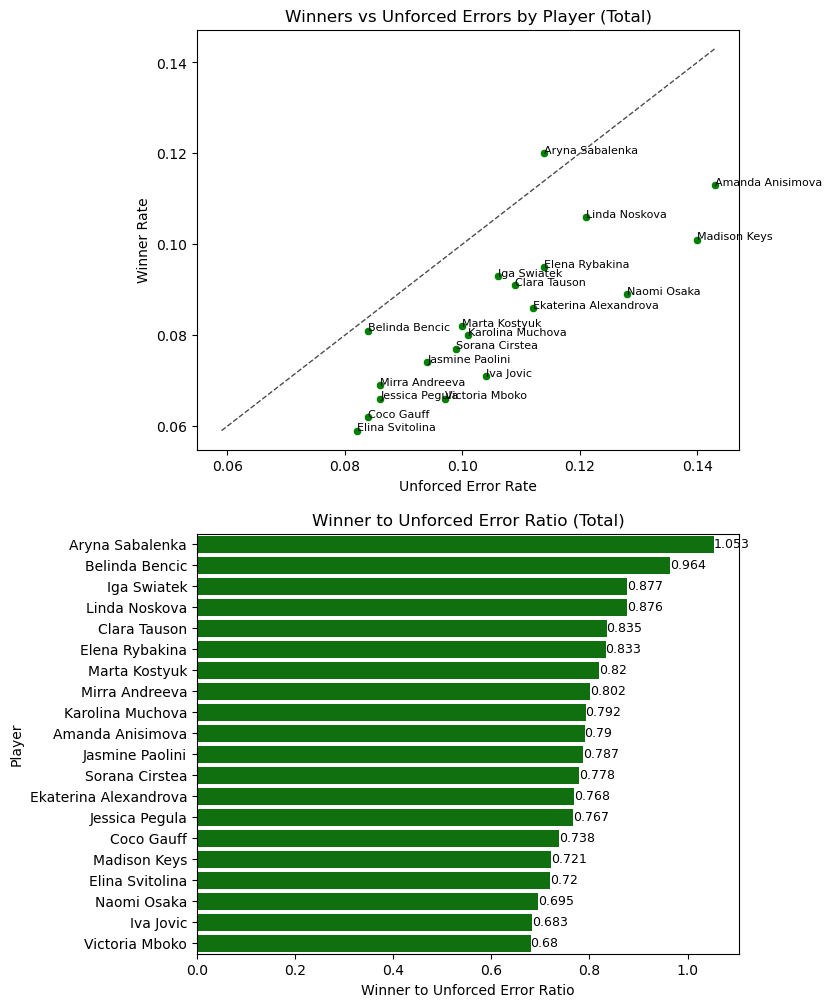

In [18]:
#Visualize the relationship between winners and unforced errors
fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (7, 12))

#Draw a scatterplot
sns.scatterplot(data = shots_total, x = "unforced_pct", y = "winners_pct", color = 'green', ax = ax[0])

#Add the line y = x
min_val = min(shots_total['unforced_pct'].min(), shots_total['winners_pct'].min())
max_val = max(shots_total['unforced_pct'].max(), shots_total['winners_pct'].max())
ax[0].plot([min_val, max_val], [min_val, max_val], 'k--', linewidth = 1, alpha = 0.7, label = 'y = x')
for x_coord, y_coord, label in zip(shots_total['unforced_pct'], 
                                   shots_total['winners_pct'], 
                                   shots_total['player']):
    ax[0].text(x_coord, y_coord, label, ha = 'left', fontsize = 8)    
ax[0].set_xlabel('Unforced Error Rate')
ax[0].set_ylabel('Winner Rate')
ax[0].set_title('Winners vs Unforced Errors by Player (Total)')

#Sort the dataframe by the 'winner_error_ratio' in descending order 
ratio_sorted = shots_total.sort_values('winner_error_ratio', ascending = False)

#Draw a barplot for winners to unforced errors ratio
sns.barplot(data = ratio_sorted, x = "winner_error_ratio", y = "player", color = 'green', ax = ax[1])
ax[1].bar_label(ax[1].containers[0], fontsize = 9)
ax[1].set_xlabel('Winner to Unforced Error Ratio')
ax[1].set_ylabel('Player')
ax[1].set_title('Winner to Unforced Error Ratio (Total)')

plt.show()

**Conclusion:** 
- Among the TOP 20 WTA players **Aryna Sabalenka** stands out as the player with the most aggressive yet controlled style of play (winner rate = 12%, unforced error rate = 11%, winner-to-unforced error ratio = 1.053).
- **Amanda Anisimova** is also an aggressive player but she makes more errors (14%) than winners (10%) with a winner-to-unforced error ratio of 0.79.
- **Elina Svitolina** and **Coco Gauff** make the fewest errors and at the same time the fewest winners. Their games are more stable.

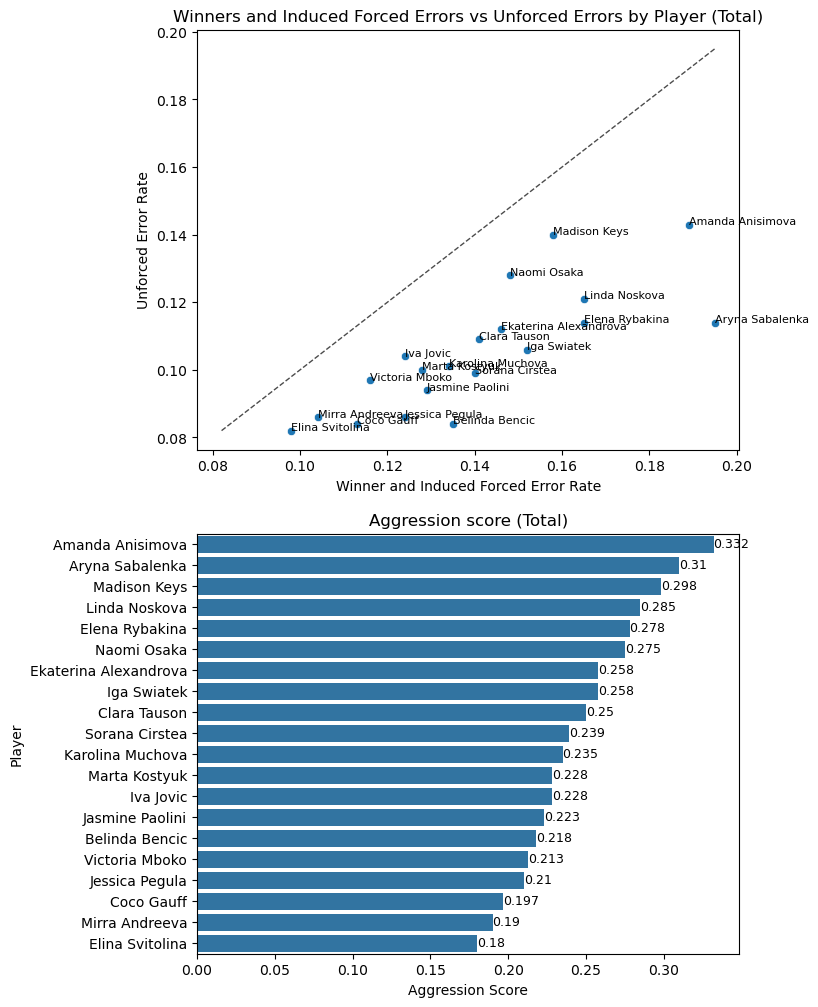

In [19]:
#Visualize the relationship between winners with induced forced errors and unforced errors
fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (7, 12))

#Draw a scatterplot 
sns.scatterplot(data = shots_total, x = "win_indf_pct", y = "unforced_pct", ax = ax[0], )

#Add the line y = x
min_val = min(shots_total['win_indf_pct'].min(), shots_total['unforced_pct'].min())
max_val = max(shots_total['win_indf_pct'].max(), shots_total['unforced_pct'].max())
ax[0].plot([min_val, max_val], [min_val, max_val], 'k--', linewidth = 1, alpha = 0.7, label = 'y = x')
for x_coord, y_coord, label in zip(shots_total['win_indf_pct'], 
                                   shots_total['unforced_pct'], 
                                   shots_total['player']):
    ax[0].text(x_coord, y_coord, label, ha = 'left', fontsize = 8)     
ax[0].set_xlabel('Winner and Induced Forced Error Rate')
ax[0].set_ylabel('Unforced Error Rate')
ax[0].set_title('Winners and Induced Forced Errors vs Unforced Errors by Player (Total)')

#Sort the dataframe by the 'agg_score' in descending order 
agg_score_sorted = shots_total.sort_values('agg_score', ascending = False)

#Draw a barplot for aggression score
sns.barplot(data = agg_score_sorted, x = "agg_score", y = "player", ax = ax[1])
ax[1].bar_label(ax[1].containers[0], fontsize = 9)
ax[1].set_xlabel('Aggression Score')
ax[1].set_ylabel('Player')
ax[1].set_title('Aggression score (Total)')

plt.show()

**Conclusion**: 
- The most aggressive players are **Amanda Anisimova** (aggression score = 0.332), **Aryna Sabalenka** (0.31) and **Madison Keys** (0.298).
- Among the WTA Top 20 the most controlled and defensive players are **Elina Svitolina** (0.18), **Mirra Andreeva** (0.19) and **Coco Gauff** (0.197).

### Analyze the relationship between variables (Forehand and Backhand Side)

Note: The **forehand side** covers groundstrokes, slices, drop shots, lobs, volleys, overheads, swing volleys and half‑volleys hit on the forehand wing. The **backhand side** includes the identical shot categories, only executed on the backhand side.

In [20]:
#Filter data to keep only shots from forehand and backhand sides
shots_fb = shots_by_player[(shots_by_player['row'] == 'Fside') | (shots_by_player['row'] == 'Bside')].reset_index(drop=True)
shots_fb.head()

,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,winner_error_diff,winners_pct,unforced_pct,win_indf_pct,winner_error_ratio,agg_margin,agg_score
0,Amanda Anisimova,Bside,6578,2015,649,483,880,1898,3451,3127,-231,0.099,0.134,0.172,0.739,252,0.306
1,Amanda Anisimova,Fside,7450,2653,941,580,1128,1786,3992,3458,-187,0.126,0.151,0.204,0.834,393,0.356
2,Aryna Sabalenka,Bside,5076,1362,464,340,557,1595,2704,2372,-93,0.091,0.110,0.158,0.827,247,0.268
3,Aryna Sabalenka,Fside,5284,1852,777,444,627,1237,2941,2343,150,0.147,0.119,0.231,1.235,594,0.350
4,Belinda Bencic,Bside,8052,1720,595,448,676,2026,4278,3774,-81,0.074,0.084,0.130,0.881,367,0.213


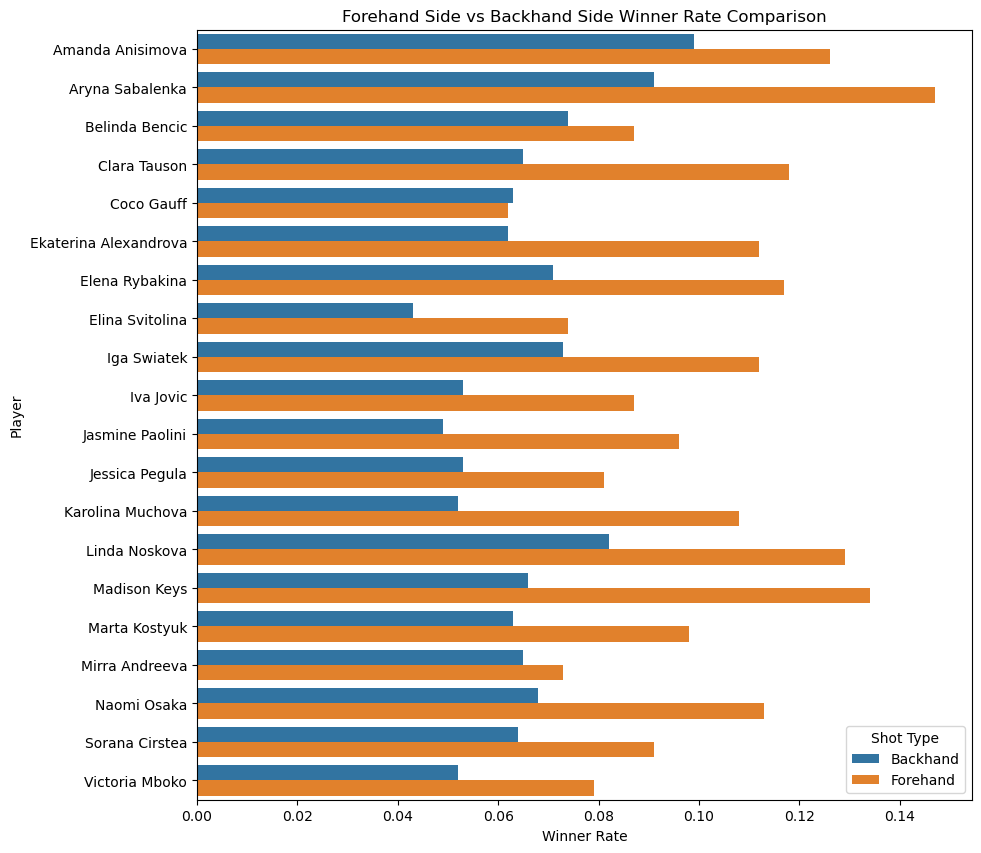

In [21]:
#Visualize forehand vs backhand winners rate comparison 
fig = plt.figure(figsize = (10,10))

sns.barplot(data = shots_fb, x = "winners_pct", y = "player", hue = 'row')
plt.xlabel('Winner Rate')
plt.ylabel('Player')
plt.title('Forehand Side vs Backhand Side Winner Rate Comparison')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, ['Backhand', 'Forehand'], title = 'Shot Type')

plt.show()

**Conclusion**: 
- Among the WTA Top 20 **Coco Gauff** is the only player who hits a slightly higher percentage of winners on the backhand (6.3%) than on the forehand (6.2%).
- **Mirra Andreeva** shows a small difference between her forehand and backhand winner rates, just 0.8% in favor of the forehand.
- For all other players in the Top 20 the gap is much larger with the forehand being the dominant wing for winners.

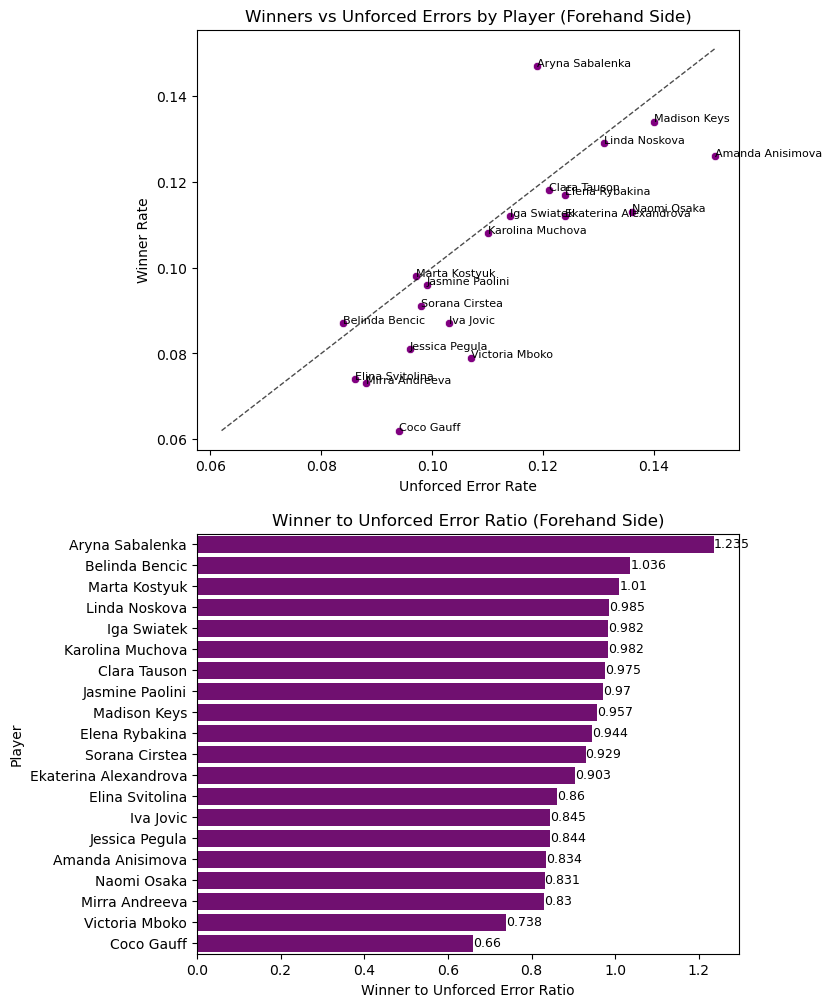

In [22]:
#Filter data to keep only shots from forehand side
shots_f = shots_by_player[(shots_by_player['row'] == 'Fside')].reset_index(drop=True)

#Visualize the relationship between winners and unforced errors
fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (7, 12))

sns.scatterplot(data = shots_f, x = "unforced_pct", y = "winners_pct", color = 'purple', ax = ax[0])

#Add the line y = x
min_val = min(shots_f['unforced_pct'].min(), shots_f['winners_pct'].min())
max_val = max(shots_f['unforced_pct'].max(), shots_f['winners_pct'].max())
ax[0].plot([min_val, max_val], [min_val, max_val], 'k--', linewidth = 1, alpha = 0.7, label = 'y = x')
for x_coord, y_coord, label in zip(shots_f['unforced_pct'], 
                                   shots_f['winners_pct'], 
                                   shots_f['player']):
    ax[0].text(x_coord, y_coord, label, ha = 'left', fontsize = 8)     
ax[0].set_xlabel('Unforced Error Rate')
ax[0].set_ylabel('Winner Rate')
ax[0].set_title('Winners vs Unforced Errors by Player (Forehand Side)')

#Sort the dataframe by the 'winner_error_ratio' in descending order 
f_ratio_sorted = shots_f.sort_values('winner_error_ratio', ascending = False)

#Draw a barplot for winners to unforced errors ratio
sns.barplot(data = f_ratio_sorted, x = "winner_error_ratio", y = "player", color = 'purple', ax = ax[1])
ax[1].bar_label(ax[1].containers[0], fontsize = 9)
ax[1].set_xlabel('Winner to Unforced Error Ratio')
ax[1].set_ylabel('Player')
ax[1].set_title('Winner to Unforced Error Ratio (Forehand Side)')

plt.show()

**Conclusion**: 
- The highest forehand winner rate belongs to **Aryna Sabalenka** (15%). The lowest forehand winner rate belongs to **Coco Gauff** (6.2%).
- By winner‑error ratio the most controlled forehand players (low errors, decent winners) are **Aryna Sabalenka** (1.235), **Belinda Bencic** (1.036) and **Marta Kostyuk** (1.01). The high‑risk forehand players (high winners but also high errors) are **Naomi Osaka** (0.831), **Amanda Anisimova** (0.834) and **Madison Keys** (0.957).

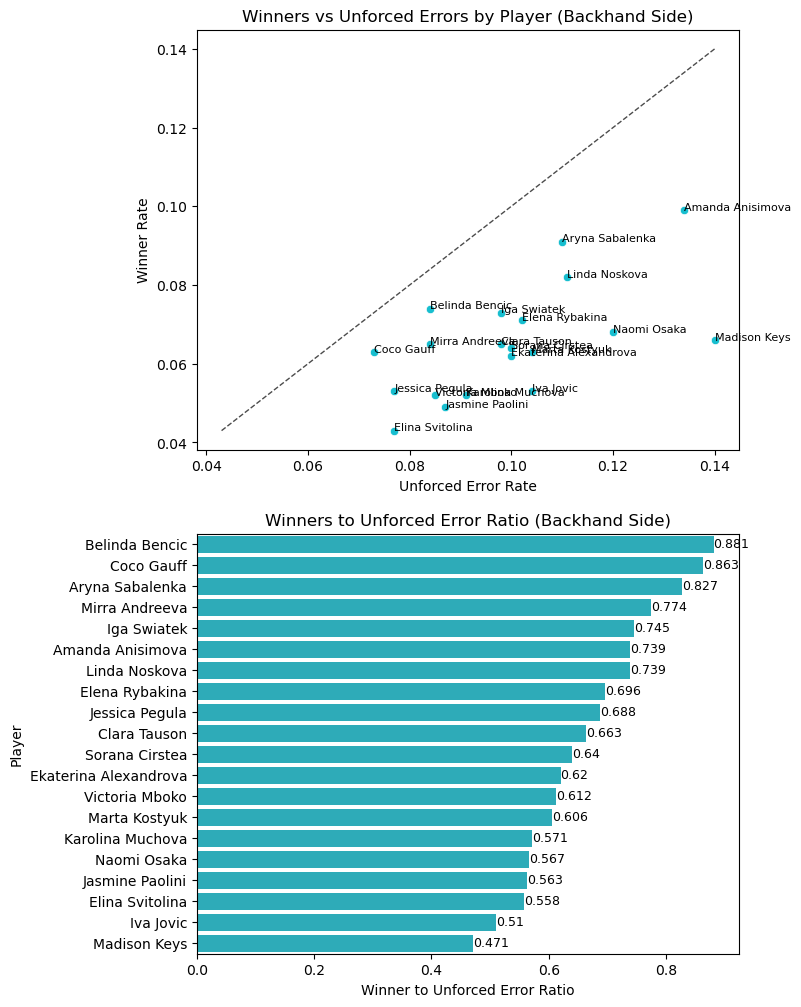

In [23]:
#Filter data to keep only shots from backhand side
shots_b = shots_by_player[(shots_by_player['row'] == 'Bside')].reset_index(drop=True)

#Visualize the relationship between winners and unforced errors
fig, ax = plt.subplots(nrows = 2, ncols = 1, figsize = (7, 12))

sns.scatterplot(data = shots_b, x = "unforced_pct", y = "winners_pct", color = 'C9', ax = ax[0])

#Add the line y = x
min_val = min(shots_b['unforced_pct'].min(), shots_b['winners_pct'].min())
max_val = max(shots_b['unforced_pct'].max(), shots_b['winners_pct'].max())
ax[0].plot([min_val, max_val], [min_val, max_val], 'k--', linewidth = 1, alpha = 0.7, label = 'y = x')
for x_coord, y_coord, label in zip(shots_b['unforced_pct'], 
                                   shots_b['winners_pct'], 
                                   shots_b['player']):
    ax[0].text(x_coord, y_coord, label, ha = 'left', fontsize = 8)    
ax[0].set_xlabel('Unforced Error Rate')
ax[0].set_ylabel('Winner Rate')
ax[0].set_title('Winners vs Unforced Errors by Player (Backhand Side)')

#Sort the dataframe by the 'winner_error_ratio' in descending order 
b_ratio_sorted = shots_b.sort_values('winner_error_ratio', ascending = False)

#Draw a barplot for winners to unforced errors ratio
sns.barplot(data = b_ratio_sorted, x = "winner_error_ratio", y = "player", color = 'C9', ax = ax[1])
ax[1].bar_label(ax[1].containers[0], fontsize = 9)
ax[1].set_xlabel('Winner to Unforced Error Ratio')
ax[1].set_ylabel('Player')
ax[1].set_title('Winners to Unforced Error Ratio (Backhand Side)')

plt.show()

**Conclusion**: 
- **Amanda Anisimova** has the highest backhand winner rate (9.9%), while **Elina Svitolina** has the lowest winner rate (4.3%).
- By winner‑error ratio the most reliable backhands belong to **Belinda Bencic** (0.881), **Coco Gauff** (0.863) and **Aryna Sabalenka** (0.827). The least efficient backhands are those of **Madison Keys** (0.471) and **Iva Jovic** (0.510).

### Compare winner rate across different shot types 

In [24]:
#Filter data to keep data about types of shots
shots_type = shots_by_player[(shots_by_player['row'] == 'F') | (shots_by_player['row'] == 'B') | \
                             (shots_by_player['row'] == 'Sl') | (shots_by_player['row'] == 'Dr') | \
                             (shots_by_player['row'] == 'Lo') | (shots_by_player['row'] == 'Vo') | \
                             (shots_by_player['row'] == 'Ov') | (shots_by_player['row'] == 'Sw') | \
                             (shots_by_player['row'] == 'Hv')].reset_index(drop=True)

#Create a dictionary to rename shot type abbreviations into full names 
rename_dict = {
    'F': 'Forehand Gr.',
    'B': 'Backhand Gr.',
    'Sl': 'Slice',
    'Dr': 'Drop shot',
    'Lo': 'Lob',
    'Vo': 'Volley',
    'Ov': 'Overhead',
    'Sw': 'Swinging Volley',
    'Hv': 'Half-Volley'
}

#Map the abbreviated shot type names to their full descriptive names using the rename dictionary
shots_type['row'] = shots_type['row'].map(rename_dict)
shots_type.head()

,player,row,shots,pt_ending,winners,induced_forced,unforced,serve_return,shots_in_pts_won,shots_in_pts_lost,winner_error_diff,winners_pct,unforced_pct,win_indf_pct,winner_error_ratio,agg_margin,agg_score
0,Amanda Anisimova,Backhand Gr.,5988,1869,586,457,823,1797,3205,2783,-237,0.098,0.137,0.174,0.715,220,0.312
1,Amanda Anisimova,Drop shot,150,70,26,14,30,3,65,85,-4,0.173,0.200,0.267,0.865,10,0.467
2,Amanda Anisimova,Forehand Gr.,6840,2408,806,541,1057,1741,3684,3156,-251,0.118,0.155,0.197,0.761,290,0.351
3,Amanda Anisimova,Half-Volley,12,7,2,2,3,0,5,7,-1,0.167,0.250,0.333,0.668,1,0.583
4,Amanda Anisimova,Lob,104,5,0,1,4,11,32,72,-4,0.000,0.038,0.010,0.000,-3,0.048


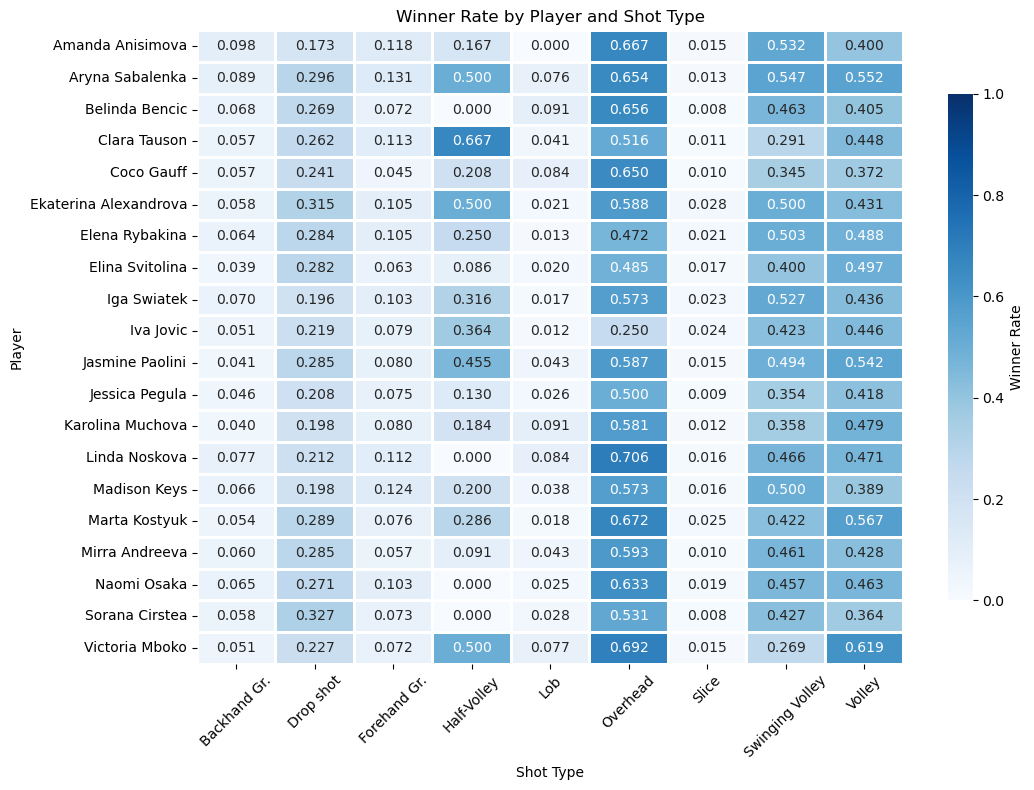

In [25]:
#Create a table by pivoting the data
heatmap_data = shots_type.pivot(index = 'player', columns = 'row', values = 'winners_pct')

#Create a heatmap
plt.figure(figsize = (11, 8))

sns.heatmap(heatmap_data, 
            annot = True, 
            fmt = '.3f',
            cmap = 'Blues',
            vmin = 0,    
            vmax = 1,
            center = 0.5,
            linewidths = 1,
            linecolor = 'white',
            cbar_kws = {'label': 'Winner Rate', 'shrink': 0.8})
plt.title('Winner Rate by Player and Shot Type')
plt.xlabel('Shot Type')
plt.ylabel('Player')
plt.xticks(rotation = 45)
plt.tight_layout()

plt.show()

**Conclusion**: 
- The highest winner rate on the forehand groundstroke belongs to **Aryna Sabalenka** (13.1%).
- **Amanda Anisimova** leads (9.8%) on the backhand groundstroke.
- For drop shots the top player is **Sorana Cirstea** (32.7%).
- **Clara Tauson** has the highest rate (66.7%) on half‑volleys.
- For lobs **Belinda Bencic** and **Karolina Muchova** share the lead (9.1% each).
- **Linda Noskova** ranks first (70.6%) on overheads.
- **Ekaterina Alexandrova** leads (2.8%) on slices.
- For swinging volleys **Aryna Sabalenka** tops the list (54.7%).
- **Victoria Mboko** has the highest winner rate (61.9%) on volleys.